<a href="https://colab.research.google.com/github/yashaswinigowdaksys/projects/blob/main/SVD_Netflix_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")



In [ ]:
from google.colab import drive

In [ ]:
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
netflix_dataset = pd.read_csv("/content/drive/MyDrive/netflix/combinedNetflixData (2).txt", header = None, names=["CustId", "Rating"], usecols = [0,1])

In [ ]:
netflix_dataset

,CustId,Rating
0,1:,NaN
1,1488844,3.0
2,822109,5.0
3,885013,4.0
4,30878,4.0
...,...,...
24058258,2591364,2.0
24058259,1791000,2.0
24058260,512536,5.0
24058261,988963,3.0


In [ ]:
netflix_dataset.head()

,CustId,Rating
0,1:,NaN
1,1488844,3.0
2,822109,5.0
3,885013,4.0
4,30878,4.0


In [ ]:
netflix_dataset.shape

(24058263, 2)

In [ ]:
netflix_dataset.isnull().sum()

,0
CustId,0
Rating,4499


In [ ]:
movie_count=netflix_dataset.isnull().sum()['Rating']

In [ ]:
movie_count

4499

In [ ]:
total_count=netflix_dataset['CustId'].nunique()
total_count

475257

In [ ]:
customer_count=total_count-movie_count
customer_count

470758

In [ ]:
total_rating=netflix_dataset['CustId'].count()-movie_count
total_rating

24053764

In [ ]:
netflix_dataset['Rating'].value_counts()

,count
Rating,
4.0,8085741
3.0,6904181
5.0,5506583
2.0,2439073
1.0,1118186


In [ ]:
movie_id=None #which we are currently reading
movie_id_per_row=[]

for i in netflix_dataset['CustId']:
  if ":"in i:
    movie_id=int(i.replace(":",""))

  movie_id_per_row.append(movie_id)

In [ ]:
movie_id_per_row

[1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 1,


In [ ]:
netflix_dataset['Movie_Id']=movie_id_per_row

In [ ]:
netflix_dataset.head()

,CustId,Rating,Movie_Id
0,1:,NaN,1
1,1488844,3.0,1
2,822109,5.0,1
3,885013,4.0,1
4,30878,4.0,1


In [ ]:
netflix_dataset.dropna(inplace=True)

In [ ]:
netflix_dataset.isnull().sum()

,0
CustId,0
Rating,0
Movie_Id,0


In [ ]:
netflix_dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 24053764 entries, 1 to 24058262
Data columns (total 3 columns):
 #   Column    Dtype  
---  ------    -----  
 0   CustId    object 
 1   Rating    float64
 2   Movie_Id  int64  
dtypes: float64(1), int64(1), object(1)
memory usage: 734.1+ MB


In [ ]:
netflix_dataset['CustId']=netflix_dataset['CustId'].astype("int")

In [ ]:
netflix_dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 24053764 entries, 1 to 24058262
Data columns (total 3 columns):
 #   Column    Dtype  
---  ------    -----  
 0   CustId    int64  
 1   Rating    float64
 2   Movie_Id  int64  
dtypes: float64(1), int64(2)
memory usage: 734.1 MB


In [ ]:
summary=netflix_dataset.groupby("Movie_Id")['Rating'].agg(['count'])
summary

,count
Movie_Id,
1,547
2,145
3,2012
4,142
5,1140
...,...
4495,614
4496,9519
4497,714


In [ ]:
movie_benchmark=round(np.percentile(summary['count'],60,method='linear'))

In [ ]:
movie_benchmark

908

In [ ]:
drop_movie_list=summary.loc[summary['count']<movie_benchmark].index

In [ ]:
drop_movie_list

Index([   1,    2,    4,    7,    9,   10,   11,   12,   13,   14,
       ...
       4480, 4481, 4486, 4487, 4491, 4494, 4495, 4497, 4498, 4499],
      dtype='int64', name='Movie_Id', length=2699)

In [ ]:
drop_movie_list = summary[summary['count']<movie_benchmark].index

In [ ]:
drop_movie_list

Index([   1,    2,    4,    7,    9,   10,   11,   12,   13,   14,
       ...
       4480, 4481, 4486, 4487, 4491, 4494, 4495, 4497, 4498, 4499],
      dtype='int64', name='Movie_Id', length=2699)

In [ ]:
netflix_dataset.columns

Index(['CustId', 'Rating', 'Movie_Id'], dtype='object')

In [ ]:
summary_cust = netflix_dataset.groupby("CustId")["Rating"].agg(['count'])
summary_cust

,count
CustId,
6,153
7,195
8,21
10,49
25,4
...,...
2649404,12
2649409,10
2649421,3


In [ ]:
cust_benchmark = round(np.percentile(summary_cust['count'], 60, method = 'linear'))

In [ ]:
cust_benchmark

36

In [ ]:
drop_cust_list = summary_cust[summary_cust['count']<cust_benchmark].index
drop_cust_list

Index([      8,      25,      33,      83,      94,     126,     130,     133,
           142,     149,
       ...
       2649337, 2649343, 2649351, 2649376, 2649379, 2649384, 2649401, 2649404,
       2649409, 2649421],
      dtype='int64', name='CustId', length=282042)

In [ ]:
netflix_dataset=netflix_dataset[~netflix_dataset['Movie_Id'].isin(drop_movie_list)]
netflix_dataset=netflix_dataset[~netflix_dataset['CustId'].isin(drop_cust_list)]

In [ ]:
netflix_dataset.shape

(19695836, 3)

#importing another dataset

In [ ]:
df_title=pd.read_csv("/content/drive/MyDrive/netflix/movies (1) (1).csv",encoding='ISO-8859-1',usecols=[0,1,2])

In [ ]:
df_title.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27278 entries, 0 to 27277
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  27278 non-null  int64 
 1   title    27278 non-null  object
 2   genres   27278 non-null  object
dtypes: int64(1), object(2)
memory usage: 639.5+ KB


In [ ]:
df_title.rename(columns={'movieId':"Movie_Id"},inplace=True)

In [ ]:
df_title.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27278 entries, 0 to 27277
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Movie_Id  27278 non-null  int64 
 1   title     27278 non-null  object
 2   genres    27278 non-null  object
dtypes: int64(1), object(2)
memory usage: 639.5+ KB


In [ ]:
#pip install numpy==1.26.4

In [ ]:
!pip install scikit-surprise

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.4/154.4 kB 7.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for scikit-surprise: filename=scikit_surprise-1.1.4-cp312-cp312-linux_x86_64.whl size=2554979 sha256=564f631759ca24afb18ddc5615bf3506b5d33a07ee6728ca3e225057a6b36b42
  Stored in directory: /root/.cache/pip/wheels/75/fa/bc/739bc2cb1fbaab6061854e6cfbb81a0ae52c92a502a7fa454b
Successfully built scikit-surprise


In [ ]:
from surprise import Reader, Dataset, SVD
from surprise.model_selection import cross_validate

In [ ]:
df_title.shape

(27278, 3)

In [ ]:
reader=Reader()

In [ ]:
data=Dataset.load_from_df(netflix_dataset[['CustId','Movie_Id','Rating']][:100000],reader)

In [ ]:
data

In [ ]:
model=SVD()

In [ ]:
cross_validate(model,data,measures=['RMSE'],cv=3)

{'test_rmse': array([1.0172924 , 1.01590237, 1.0194412 ]),
 'fit_time': (1.7114322185516357, 1.9719316959381104, 1.437760591506958),
 'test_time': (0.6994645595550537, 0.6138637065887451, 0.14449620246887207)}

In [ ]:
#id-1331154

user_rating=netflix_dataset[(netflix_dataset['CustId']==1331154)]

In [ ]:
user_rating

,CustId,Rating,Movie_Id
697,1331154,4.0,3
5178,1331154,4.0,8
31460,1331154,3.0,18
92840,1331154,4.0,30
224761,1331154,3.0,44
...,...,...,...
23439584,1331154,4.0,4389
23546489,1331154,2.0,4402
23649431,1331154,4.0,4432
23844441,1331154,3.0,4472


In [ ]:
user_1331154 = df_title.copy()
user_1331154

,Movie_Id,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy
...,...,...,...
27273,131254,Kein Bund fÃ¼r's Leben (2007),Comedy
27274,131256,"Feuer, Eis & Dosenbier (2002)",Comedy
27275,131258,The Pirates (2014),Adventure
27276,131260,Rentun Ruusu (2001),(no genres listed)


In [ ]:
# Remove the less rate movies

user_1331154 = user_1331154[~user_1331154 ['Movie_Id']. isin(drop_movie_list)]

In [ ]:
user_1331154

,Movie_Id,title,genres
2,3,Grumpier Old Men (1995),Comedy|Romance
4,5,Father of the Bride Part II (1995),Comedy
5,6,Heat (1995),Action|Crime|Thriller
7,8,Tom and Huck (1995),Adventure|Children
15,16,Casino (1995),Crime|Drama
...,...,...,...
27273,131254,Kein Bund fÃ¼r's Leben (2007),Comedy
27274,131256,"Feuer, Eis & Dosenbier (2002)",Comedy
27275,131258,The Pirates (2014),Adventure
27276,131260,Rentun Ruusu (2001),(no genres listed)


In [ ]:
user_1331154['Estimated_Score'] = user_1331154['Movie_Id'].apply(lambda x:model.predict(1331154,x).est)

In [ ]:
user_1331154['Estimated_Score']

,Estimated_Score
2,3.862515
4,3.673530
5,3.269186
7,3.725840
15,3.310292
...,...
27273,3.695449
27274,3.695449
27275,3.695449
27276,3.695449


In [ ]:
user_1331154.sort_values("Estimated_Score", ascending = False, inplace =True)

In [ ]:
user_1331154.head()

,Movie_Id,title,genres,Estimated_Score
17,18,Four Rooms (1995),Comedy,4.188856
24,25,Leaving Las Vegas (1995),Drama|Romance,4.051490
27,28,Persuasion (1995),Drama|Romance,3.906990
2,3,Grumpier Old Men (1995),Comedy|Romance,3.862515
29,30,Shanghai Triad (Yao a yao yao dao waipo qiao) ...,Crime|Drama,3.776202


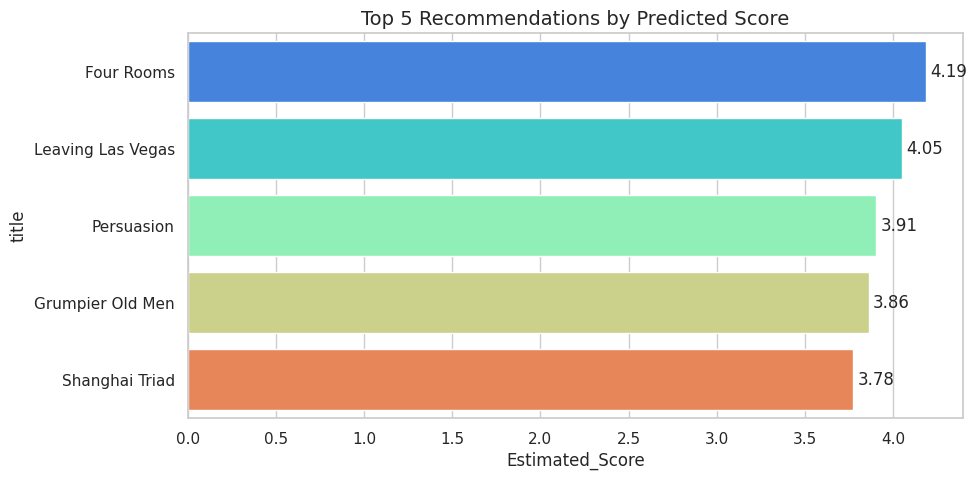

In [ ]:

data = {
    'title': ['Four Rooms', 'Leaving Las Vegas', 'Persuasion', 'Grumpier Old Men', 'Shanghai Triad'],
    'Estimated_Score': [4.188856, 4.051490, 3.906990, 3.862515, 3.776202]
}
df_new = pd.DataFrame(data)


sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))

# Plot
ax = sns.barplot(x='Estimated_Score', y='title', data=df_new, palette='rainbow')

# Add score labels to the end of the bars
for i in ax.containers:
    ax.bar_label(i, padding=3, fmt='%.2f')

plt.title('Top 5 Recommendations by Predicted Score', fontsize=14)
plt.show()


In [ ]:
user_1331154['genres']

,genres
17,Comedy
24,Drama|Romance
27,Drama|Romance
2,Comedy|Romance
29,Crime|Drama
...,...
15,Crime|Drama
5,Action|Crime|Thriller
23,Drama|Sci-Fi
25,Drama


In [ ]:
data = df_new.assign(genres=df_new['genres'].str.split('|')).explode('genres')

# Calculate popularity (count) and preference (mean score)
genres = data.groupby('genres')['Estimated_Score'].agg(['count', 'mean']).sort_values(by='mean', ascending=False)

print("Most Popular Genre (by frequency):", user_1331154['count'].idxmax())
print("Most Liked Genre (by highest avg score):", user_1331154['mean'].idxmax())

KeyError: 'genres'